# Figures of *Spectral analysis of the Koopman operator as a framework for recovering Hamiltonian parameters in open quantum systems*

J. E. Pérez-García, C. Colchero, and J. C. Gutiérrez-Vega, **Phys. Rev. A 113, 042222 (2026)**.

We would greatly appreciate if you could please cite both the Phys. Rev. A and the original mHAVOK papers in your research; it'll help us a lot. The original mHAVOK paper can be found here: https://doi.org/10.1063/5.0303718. 

This notebook regenerates every plot of the paper by calling two modules:

| file | contents |
|---|---|
| `jhavok_setup.py` | Lindblad simulations (QuTiP), mHAVOK, optimal-rank selection, spectral analysis of **A**, matrix-pencil/FFT baselines and the parameter sweeps |
| `jhavok_plots.py` | one `plot_figN` function per figure, with the published styling |
| `data/` | the CSVs behind Figs. 3 and 5 |
| `figures/` | PDFs written by this notebook when `SAVE_FIGS = True` |

Running everything takes about 5 minutes (the Jaynes-Cummings simulation is the slowest). See `README.md` for parameters and notes on how the code compares with the text of the paper.

In [24]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path

import numpy as np

import jhavok_setup as js     # autoreload picks up edits to the modules without restarting
import jhavok_plots as jp

SAVE_FIGS = True            # write each figure to figures/FigN.pdf
RECOMPUTE_SWEEPS = False    # True re-runs the sweeps of Figs. 3 and 5 (about an hour)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("data")

def out(name):
    return FIG_DIR / f"{name}.pdf" if SAVE_FIGS else None

dt, t = js.DT, js.time_grid()   # Table I: dt = 0.01, t_f = 50

## Fig. 2 — open 2D quantum harmonic oscillator (Sec. IV A)

Quadratures $[\langle x\rangle, \langle y\rangle, \langle p_x\rangle, \langle p_y\rangle]$ of the 2D QHO in a common thermal bath (Table I), for $\kappa = 0.1$ and $\kappa = 1.0$, without nonlinearities. mHAVOK with $r = 4$ and $m = 25$ delays (100 Hankel rows).

In [25]:
_, traj_k01 = js.simulate_2d_qho(kappa=0.1)
_, traj_k1 = js.simulate_2d_qho(kappa=1.0)
qho = {0.1: js.run_mhavok(traj_k01, dt, r=4),
       1.0: js.run_mhavok(traj_k1, dt, r=4)}

for kappa, res in qho.items():
    p = js.extract_params_from_A(res.A)
    e_w = 0.5 * (js.percent_error(p["omega_x_est"], js.OMEGA_X)
                 + js.percent_error(p["omega_y_est"], js.OMEGA_Y))
    print(f"kappa = {kappa}: eigenvalues of A = {np.round(res.eigenvalues, 4)}")
    print(f"    e_omega = {e_w:.3g} %,  e_kappa = {js.percent_error(p['kappa_est'], kappa):.2g} %")

print("\nSchur form of A (kappa = 0.1):")
print(js.analyze_linear_oscillators(qho[0.1].A)["A_canon"].round(4))

kappa = 0.1: eigenvalues of A = [-0.1+3.1448j -0.1-3.1448j -0.1+6.28j   -0.1-6.28j  ]
    e_omega = 0.0761 %,  e_kappa = 0.00084 %
kappa = 1.0: eigenvalues of A = [-1.+3.501j  -1.-3.501j  -1.+5.9238j -1.-5.9238j]
    e_omega = 8.58 %,  e_kappa = 7.8e-05 %

Schur form of A (kappa = 0.1):
[[-0.1     6.28    0.      0.    ]
 [-6.28   -0.1     0.      0.    ]
 [ 0.      0.     -0.1     3.1448]
 [ 0.      0.     -3.1448 -0.1   ]]


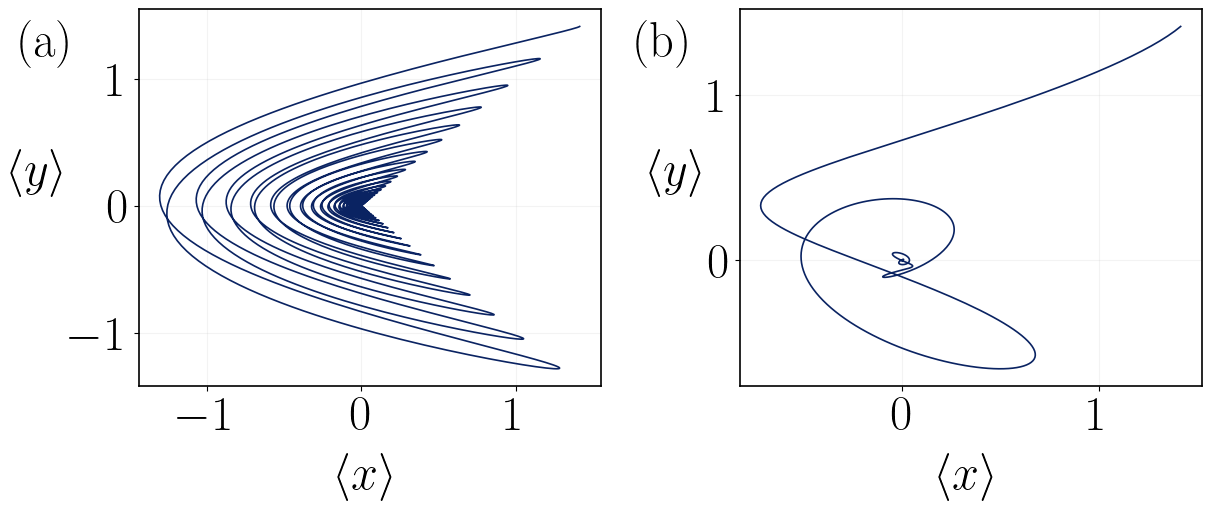

In [26]:
fig2 = jp.plot_fig2_qho_phase_space(qho[0.1].x_recovered, qho[1.0].x_recovered,
                                    save_path=out("Fig2"))

## Fig. 3 — mHAVOK vs. matrix pencil vs. FFT

Average oscillation-frequency error against $\kappa$ for the 2D QHO without Kerr terms. Plotted from the CSV used in the paper; set `RECOMPUTE_SWEEPS = True` to regenerate it (the new CSV goes to `data/recomputed/`, the original is never overwritten).

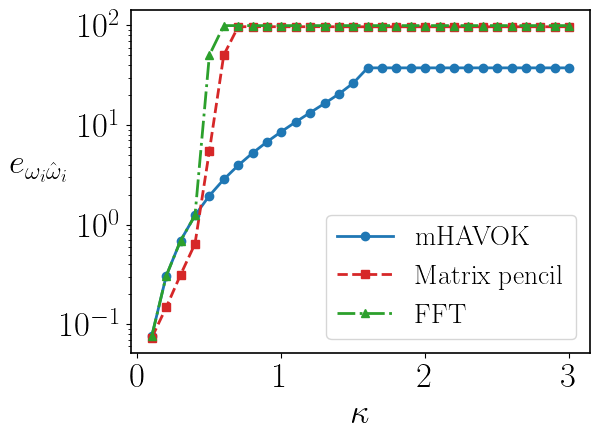

In [27]:
fig3_csv = DATA_DIR / "fig3_kappa_sweep_no_kerr.csv"
if RECOMPUTE_SWEEPS:
    (DATA_DIR / "recomputed").mkdir(exist_ok=True)
    fig3_csv = DATA_DIR / "recomputed" / "fig3_kappa_sweep_no_kerr.csv"
    js.sweep_kappa(np.round(np.arange(0.1, 3.0 + 1e-9, 0.1), 3), r=4, save_csv_path=fig3_csv)

fig3 = jp.plot_fig3_method_comparison(fig3_csv, save_path=out("Fig3"))

## Fig. 4 — Kerr nonlinearities (Sec. IV B)

Open system with $\kappa = 0.1$, $T = 2$ and $\chi_{xy} = 0$:

* (a), (c): $(\chi_x, \chi_y) = (2, 3)$, reconstructed with $r = 30$.
* (b), (d): the stronger-Kerr run. In the original simulation the $\chi = (5, 5)$ Kerr term was added on top of the $\chi = (2, 3)$ Hamiltonian, so the simulated system has $(\chi_x, \chi_y) = (7, 8)$; reconstructed with $r = 25$.

In [28]:
# chi = (2, 3), and the stronger-Kerr run: chi = (5, 5) added on top of (2, 3) -> chi = (7, 8)
_, traj = js.simulate_2d_qho(chi_x=2, chi_y=3, kappa=0.1)
_, traj1 = js.simulate_2d_qho(chi_x=2 + 5, chi_y=3 + 5, kappa=0.1)

kerr = js.run_mhavok(traj, dt, r=30)
kerr1 = js.run_mhavok(traj1, dt, r=25)

for label, res in [("traj  (chi = (2, 3))", kerr), ("traj1 (chi = (7, 8))", kerr1)]:
    print(f"{label}: r = {res.r}, {len(res.good_dims)} linear + "
          f"{len(res.forcing_dims)} nonlinear modes, mean R^2 = {res.r2_mean:.6f}")

traj  (chi = (2, 3)): r = 30, 27 linear + 3 nonlinear modes, mean R^2 = 0.996157
traj1 (chi = (7, 8)): r = 25, 21 linear + 4 nonlinear modes, mean R^2 = 0.999665


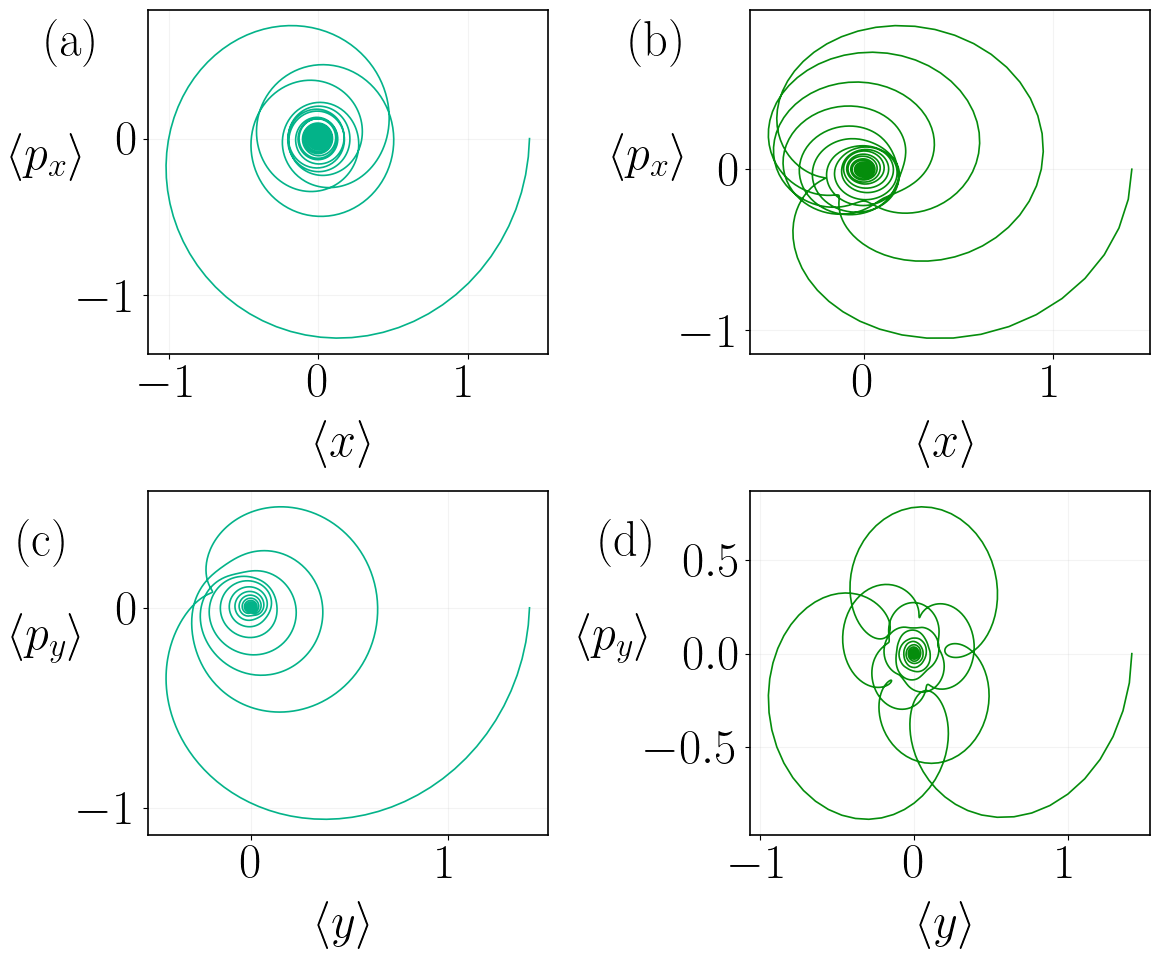

In [29]:
fig4 = jp.plot_fig4_kerr_phase_space(kerr.x_recovered, kerr1.x_recovered, save_path=out("Fig4"))

## Fig. 5 — Kerr-strength error map and method comparison with Kerr terms

(a) Mean error of $\hat\chi_x, \hat\chi_y$ over a $10\times10$ grid of $\chi_x, \chi_y \in [3, 5]$. (b) Same comparison as Fig. 3 with $(\chi_x, \chi_y) = (2, 3)$. Both panels are plotted from the paper's CSVs.

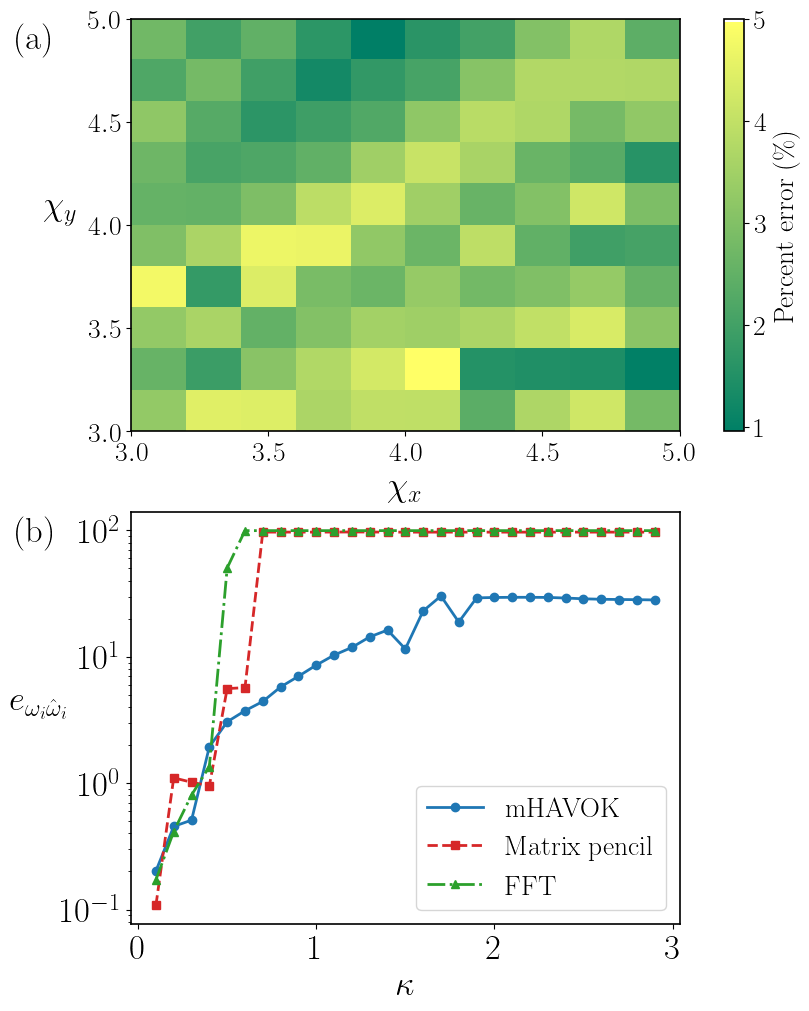

In [30]:
fig5a_csv = DATA_DIR / "fig5a_kerr_sweep.csv"
fig5b_csv = DATA_DIR / "fig5b_kappa_sweep_kerr.csv"
if RECOMPUTE_SWEEPS:
    (DATA_DIR / "recomputed").mkdir(exist_ok=True)
    fig5a_csv = DATA_DIR / "recomputed" / "fig5a_kerr_sweep.csv"
    fig5b_csv = DATA_DIR / "recomputed" / "fig5b_kappa_sweep_kerr.csv"
    chis = np.linspace(3, 5, 10)
    js.sweep_kerr_grid(chis, chis, r="auto", save_csv_path=fig5a_csv)
    js.sweep_kappa(np.round(np.arange(0.1, 3.0, 0.1), 3), chi_x=2, chi_y=3, r=20,
                   save_csv_path=fig5b_csv)

fig5 = jp.plot_fig5_kerr_errors(fig5a_csv, fig5b_csv, save_path=out("Fig5"))

## Fig. 6 — closed Kerr oscillator: sensitivity to the cutoff rank

Closed system (no jump operators), built the same way as Fig. 4:

* light panels (b), (d): $(\chi_x, \chi_y) = (5, 5)$, reconstructed with $r = 30$.
* dark panels (a), (c): the $\chi = (5, 5)$ Kerr term added again on top, i.e. $(\chi_x, \chi_y) = (10, 10)$, reconstructed with $r = 25$.

The column titles are kept as published ($r = 13$ and $r_\mathrm{opt} = 16$); the ranks actually used are printed below.

dark:  traj1 (chi = (10, 10)): r = 25, 24 linear + 1 nonlinear modes, mean R^2 = 0.9803
light: traj  (chi = (5, 5)): r = 30, 30 linear + 0 nonlinear modes, mean R^2 = 0.9980


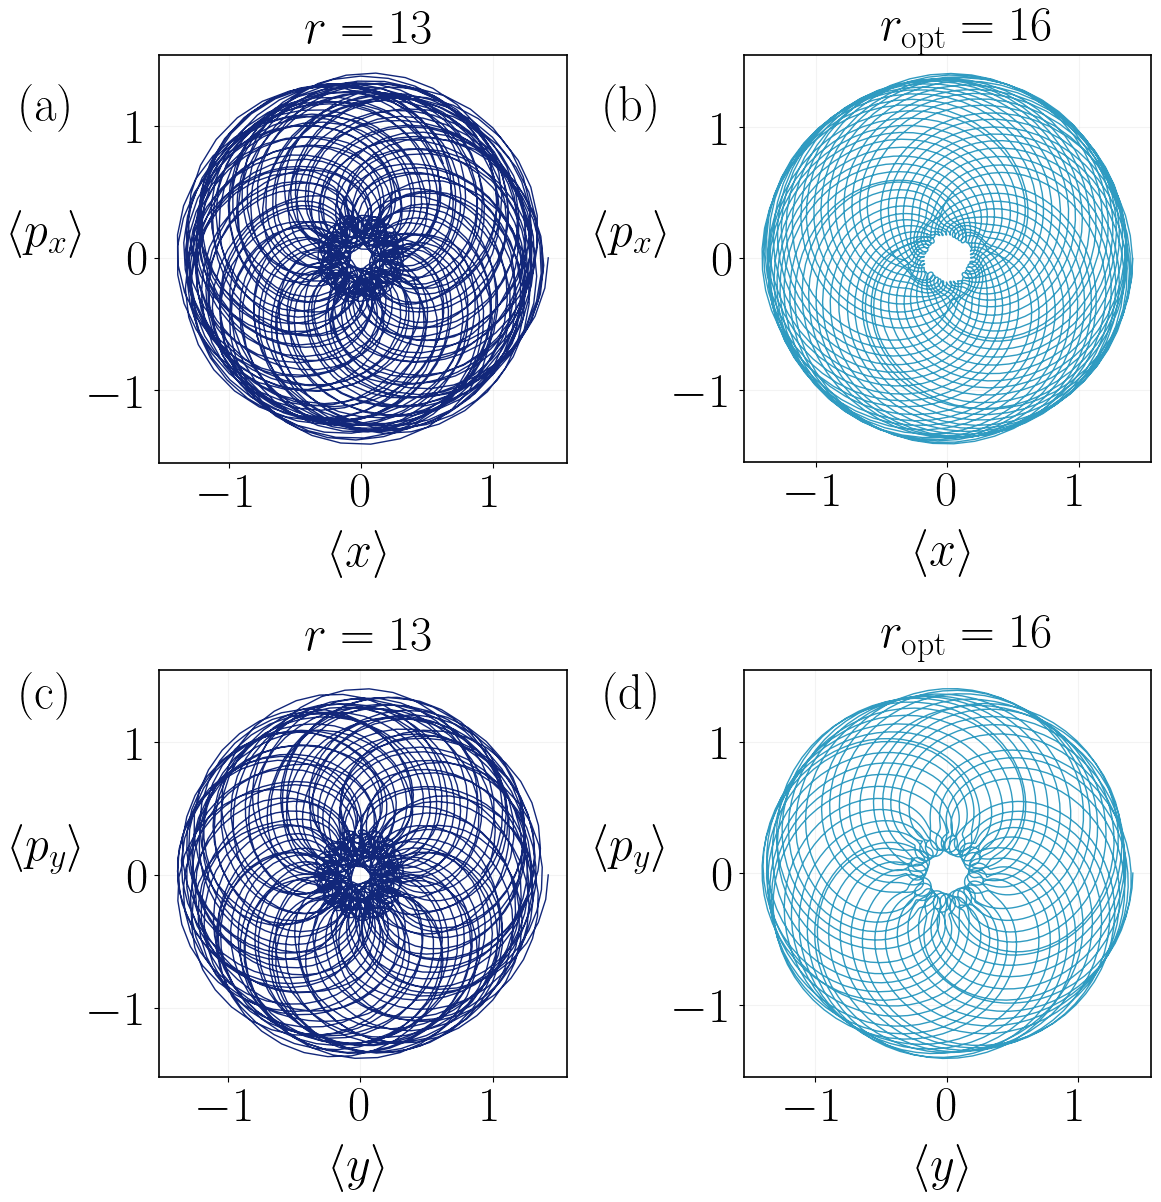

In [31]:
# Closed system: chi = (5, 5), and chi = (5, 5) added on top -> chi = (10, 10)
_, traj_c = js.simulate_2d_qho(chi_x=5, chi_y=5, open_system=False)
_, traj1_c = js.simulate_2d_qho(chi_x=5 + 5, chi_y=5 + 5, open_system=False)

closed = js.run_mhavok(traj_c, dt, r=30)      # light panels
closed1 = js.run_mhavok(traj1_c, dt, r=25)    # dark panels

for label, res in [("dark:  traj1 (chi = (10, 10))", closed1), ("light: traj  (chi = (5, 5))", closed)]:
    print(f"{label}: r = {res.r}, {len(res.good_dims)} linear + "
          f"{len(res.forcing_dims)} nonlinear modes, mean R^2 = {res.r2_mean:.4f}")

fig6 = jp.plot_fig6_closed_kerr_rank(closed1.x_recovered, closed.x_recovered, save_path=out("Fig6"))

## Fig. 7 — Jaynes-Cummings interaction (Sec. IV C)

Qubit coupled to the $x$ mode with $g = 0.15$, $\omega_q = 2\pi$, $\gamma = 0.1$, $\gamma_\phi = 0.01$. mHAVOK receives the six channels of Eq. (50) ($m = 17$ delays) with $r = 20$. $\hat g$ is obtained by inverting Eq. (49) with the lower dressed frequency $\hat\omega_-$ read from the spectrum of **A**.

In [32]:
g, omega_q = 0.15, 2 * np.pi
_, traj_jc = js.simulate_jaynes_cummings(g=g, omega_q=omega_q, gamma_relax=0.1, gamma_phi=0.01)
jc = js.run_mhavok(traj_jc, dt, r=20)

g_hat, omega_minus_hat = js.estimate_jc_coupling(jc.A, js.OMEGA_X, omega_q)
print(f"{len(jc.good_dims)} linear + {len(jc.forcing_dims)} nonlinear modes, mean R^2 = {jc.r2_mean:.6f}")
print(f"omega_- = {js.dressed_frequencies(js.OMEGA_X, omega_q, g)[1]:.4f}, "
      f"omega_-_hat = {omega_minus_hat:.4f}")
print(f"g = {g}, g_hat = {g_hat:.3f}  (e_g = {js.percent_error(g_hat, g):.1f} %)")

16 linear + 4 nonlinear modes, mean R^2 = 0.999950
omega_- = 6.1332, omega_-_hat = 6.1493
g = 0.15, g_hat = 0.134  (e_g = 10.8 %)


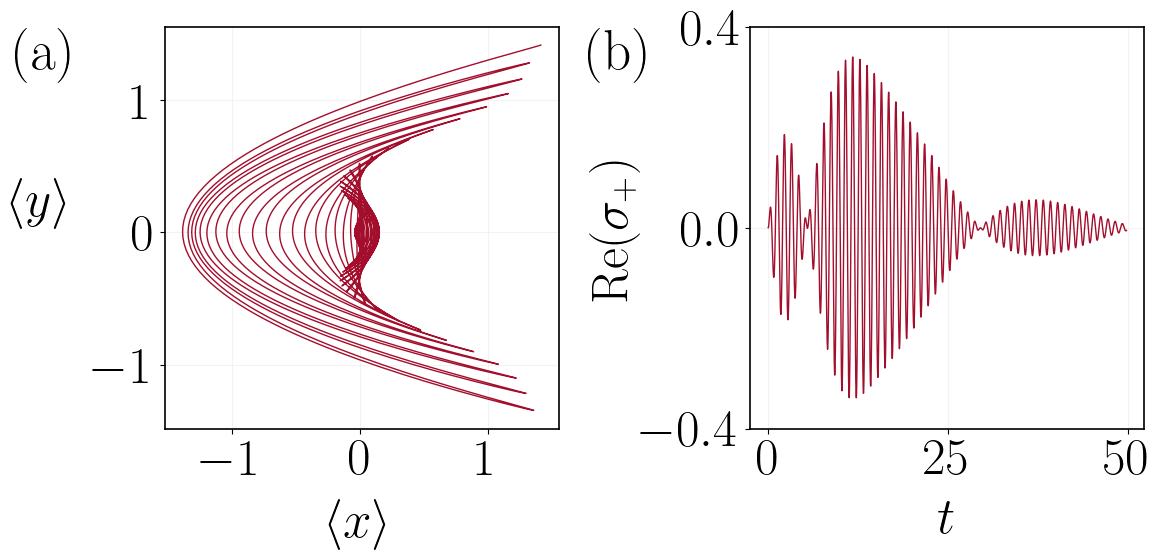

In [33]:
fig7 = jp.plot_fig7_jaynes_cummings(t, jc.x_recovered, save_path=out("Fig7"))

## Fig. 8 — parametric frequency modulation (Sec. IV D)

$H_f(t) = \delta\cos(\omega_f t)\,a_x^\dagger a_x$ with $\omega_f = \pi/e$ and $r = 10$. The published spectrum was produced with $\delta = 0.25$ (with $\delta = 0.25$ the recovered $\hat\omega_f$ has the 1.74 % error quoted in the text).

In [34]:
omega_f = np.pi / np.e
_, traj_mod = js.simulate_modulated_qho(delta=0.25, omega_f=omega_f)
mod = js.run_mhavok(traj_mod, dt, r=10)

w = np.abs(mod.eigenvalues.imag)          # [w_y, w_y, w_x - w_f, ..., w_x, ..., w_x + w_f, ...]
omega_f_hat = w[4] - w[2]                  # w_x - (w_x - w_f)
print("eigenvalues of A:", np.round(mod.eigenvalues, 4))
print(f"omega_f = {omega_f:.4f}, omega_f_hat = {omega_f_hat:.4f} "
      f"(error {js.percent_error(omega_f_hat, omega_f):.2f} %)")

eigenvalues of A: [-0.05  +3.1424j -0.05  -3.1424j -0.0302+5.1067j -0.0302-5.1067j
 -0.0463+6.2826j -0.0463-6.2826j -0.0744+7.4531j -0.0744-7.4531j]
omega_f = 1.1557, omega_f_hat = 1.1759 (error 1.74 %)


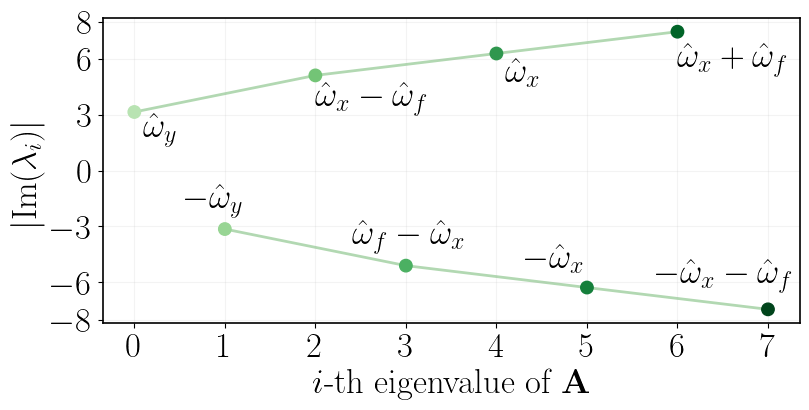

In [35]:
fig8 = jp.plot_fig8_modulated_spectrum(mod.A, save_path=out("Fig8"))